In [82]:
import os
import pathlib
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import numpy as np
from scipy.stats import kendalltau

In [127]:
brightness_cats = ["MOS",'brightness_subjective', 'brightness_mean', 'brightness_hsv' ]
contrast_cats = ["MOS",'contrast_subjective', 'contrast_rms','contrast_michelson','contrast_rms_smoothed']
colorful_cats = ["MOS",'colorfulness_subjective', 'colorfulness_hs','colorfulness_hs_smoothed','colorfulness_lab','colorfulness_hsv','colorfulness_entropy']
sharpness_cats = ["MOS",'sharpness_subjective','sharpness_laplacian','sharpness_laplacian_bilateral','sharpness_tenengrad','sharpness_tenengrad_variance','sharpness_entropy','sharpness_hfer']
noise_cats = ['MOS','gaussian_noise', 'median_noise', 'gaussian_snr']

MOS_subjectives = ["MOS", 'brightness_subjective','contrast_subjective','colorfulness_subjective','sharpness_subjective',]

all_cats = [brightness_cats, contrast_cats, colorful_cats, sharpness_cats, noise_cats, MOS_subjectives]

In [125]:
output_folder = Path('output/')
df = pd.read_csv(output_folder/'processed_merged.csv')

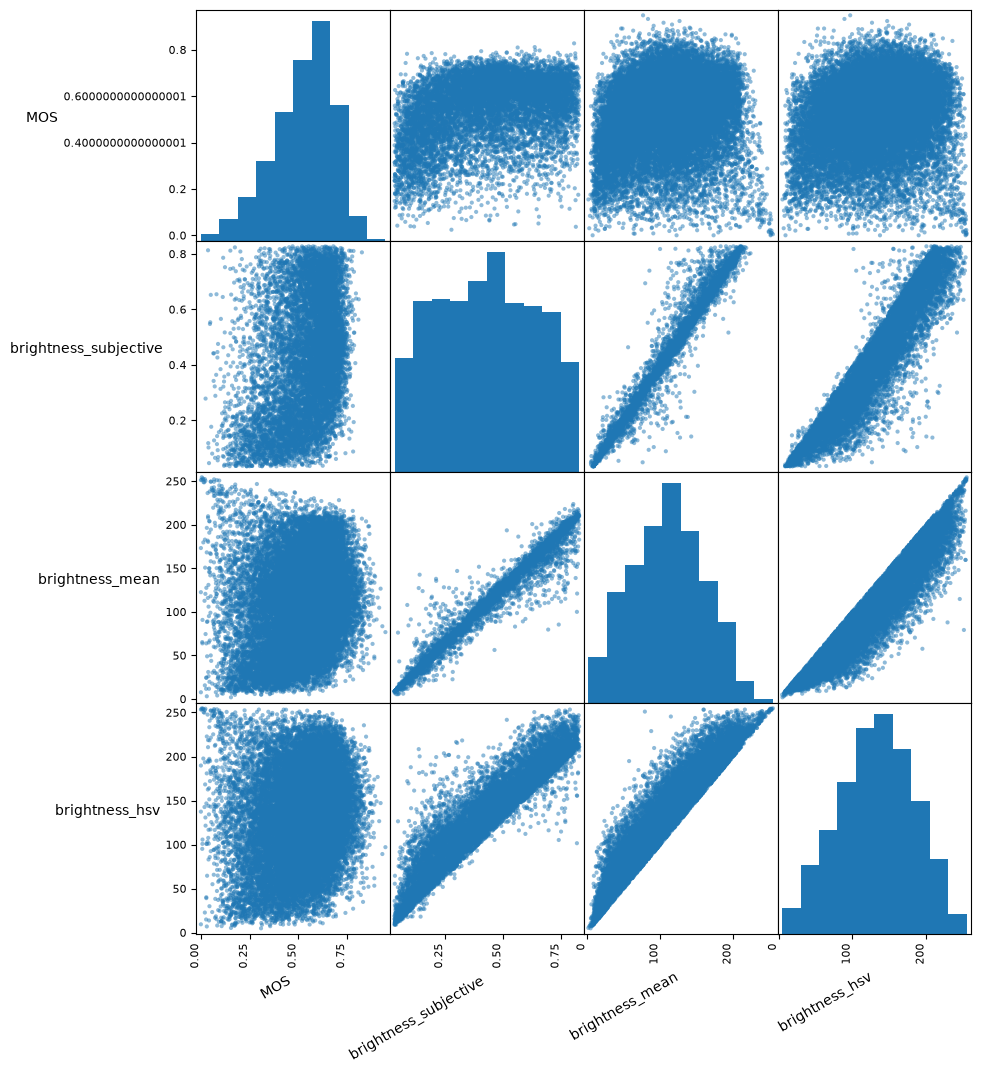

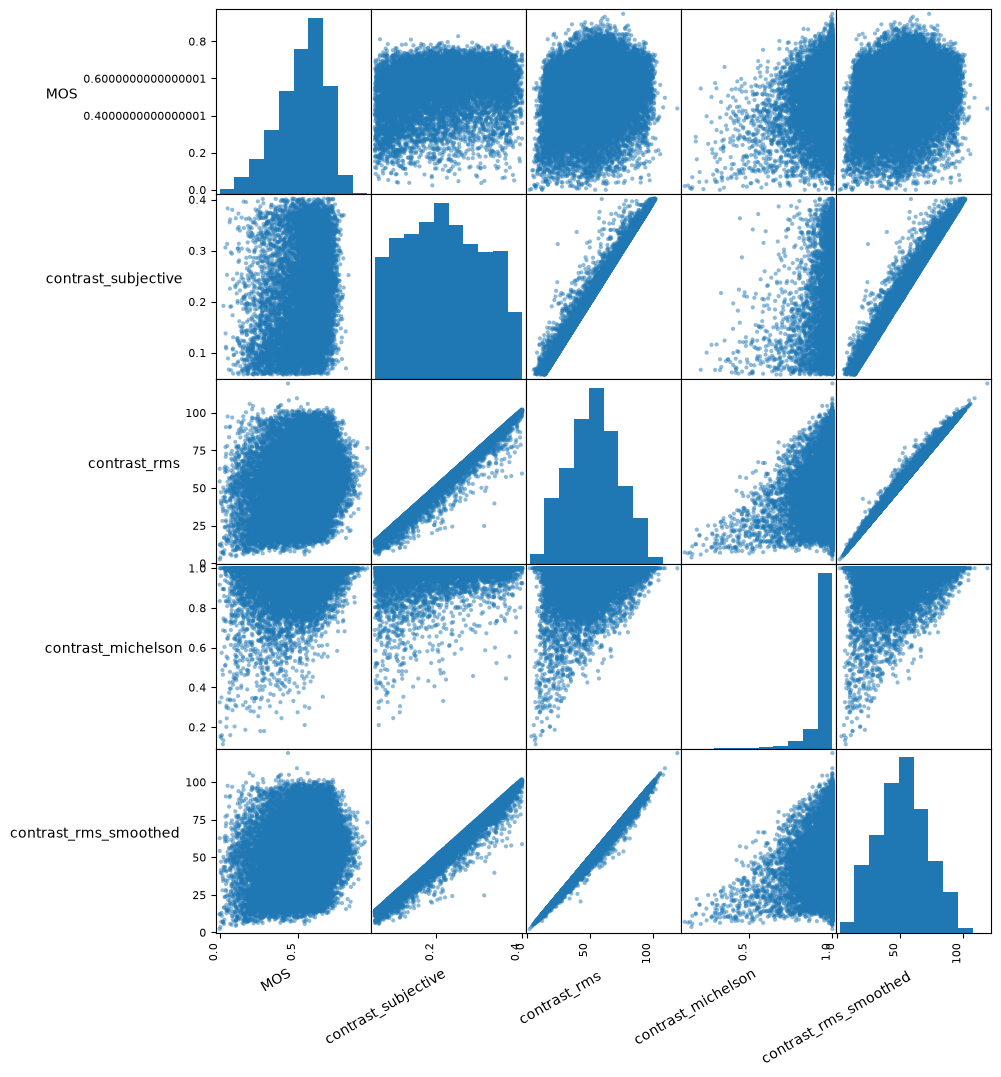

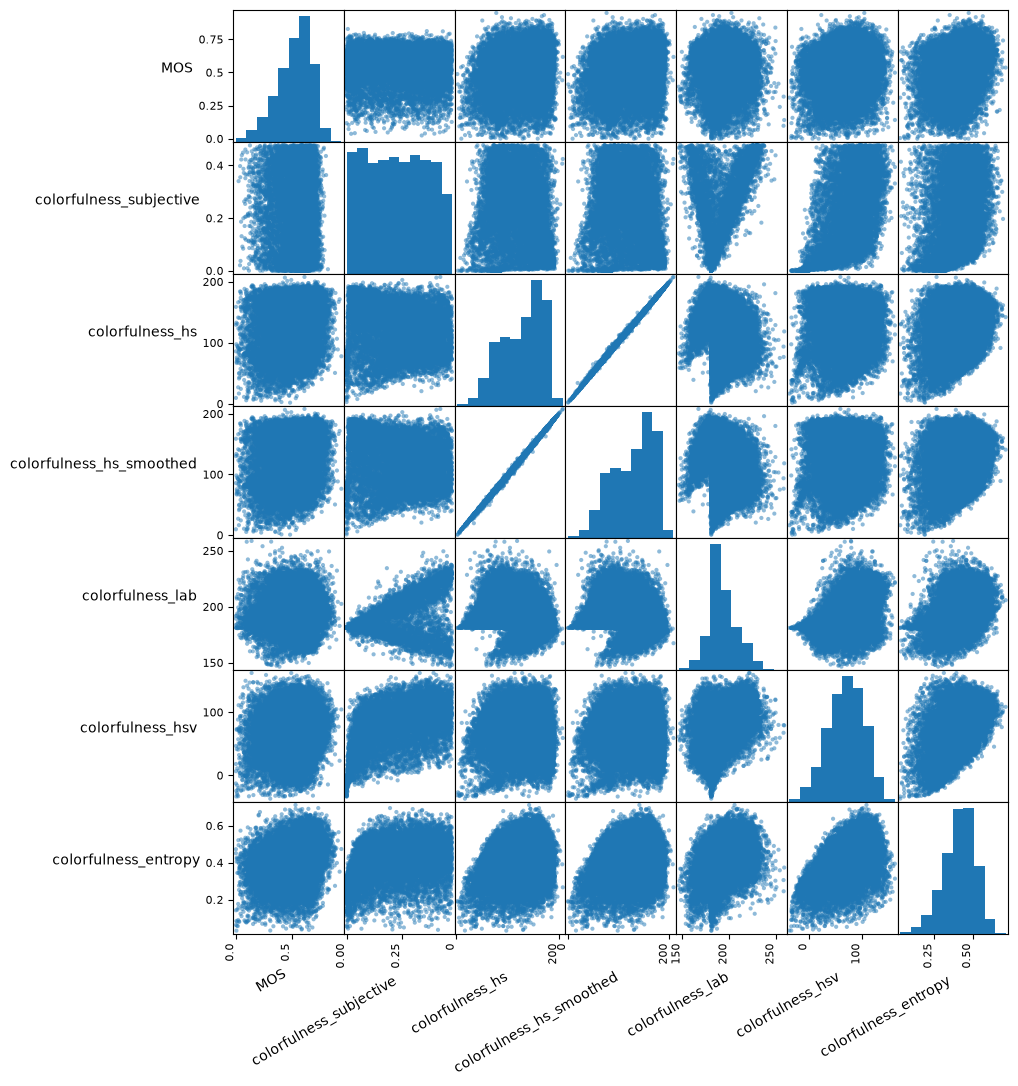

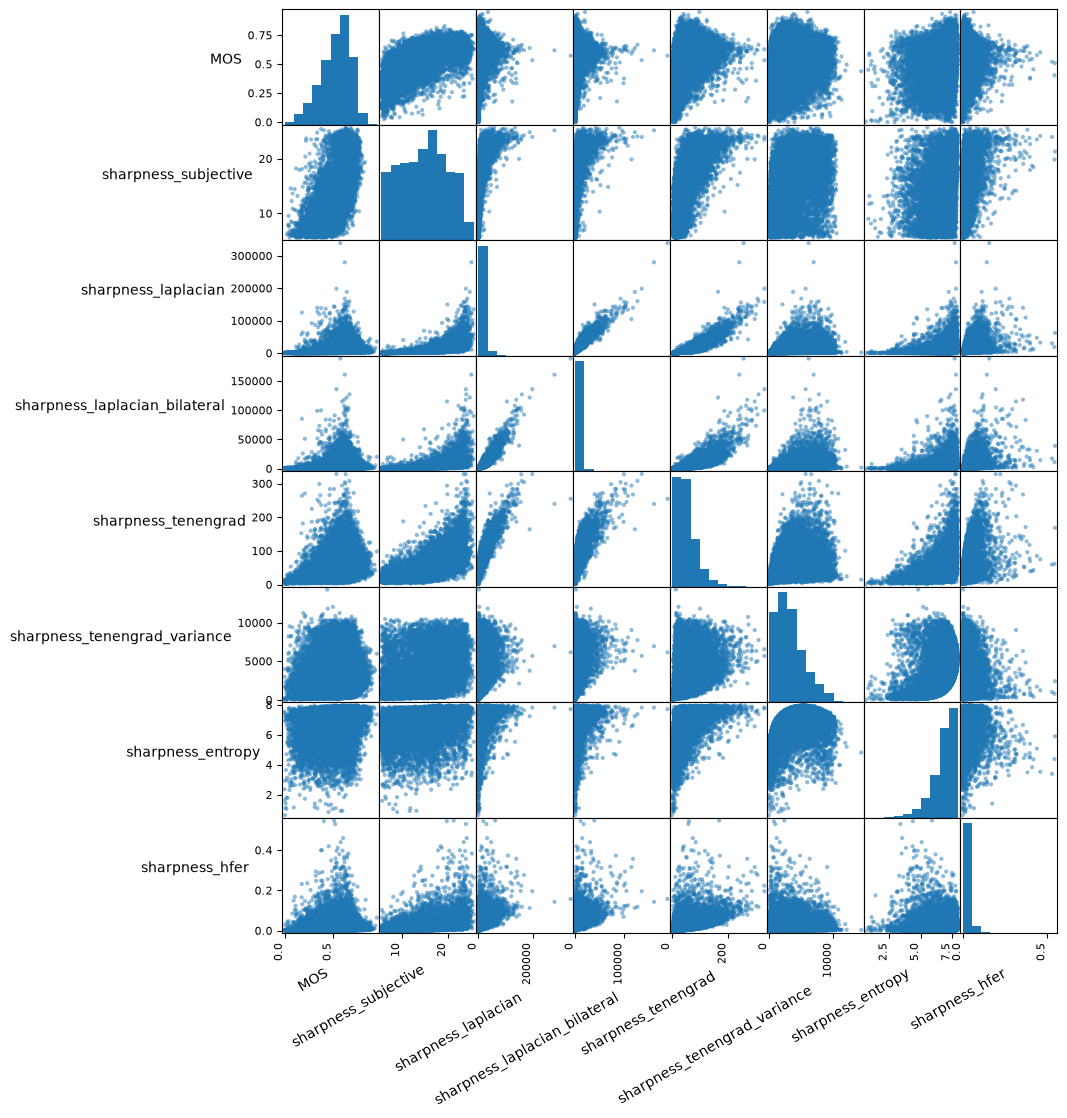

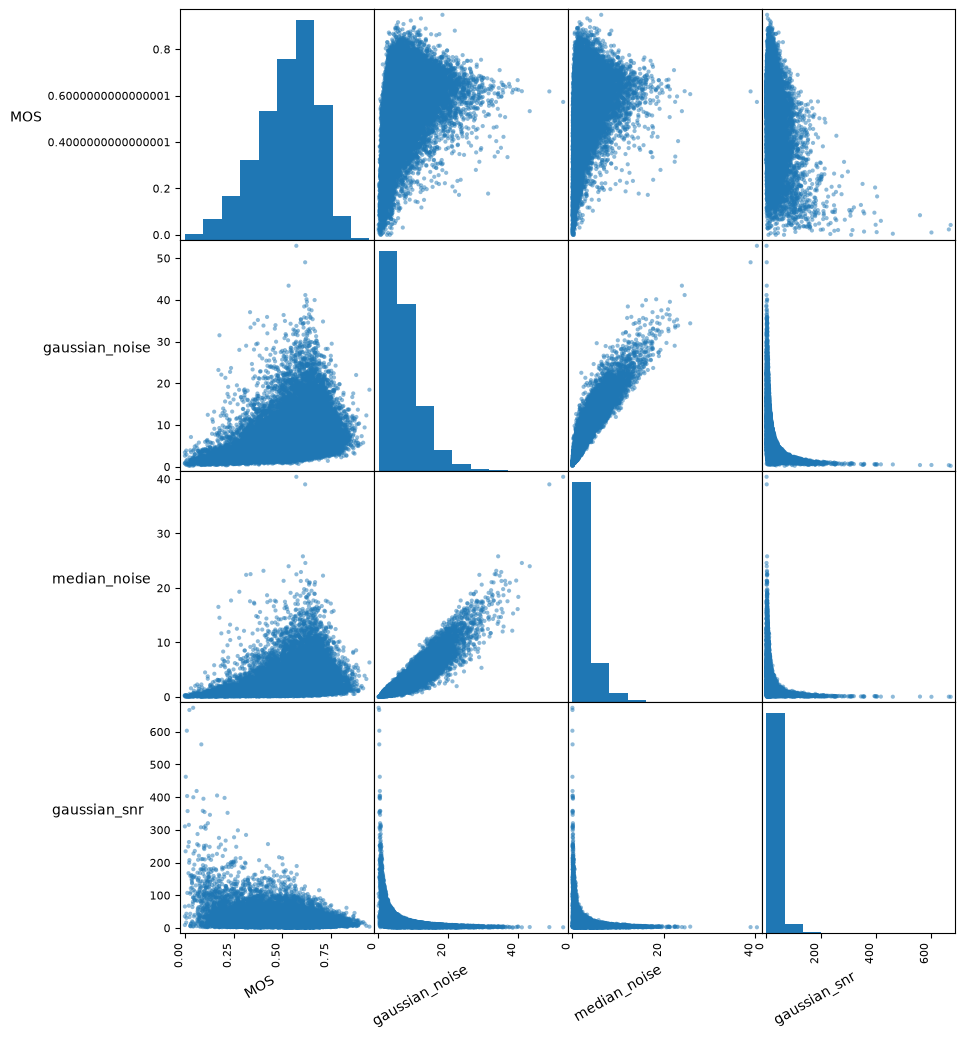

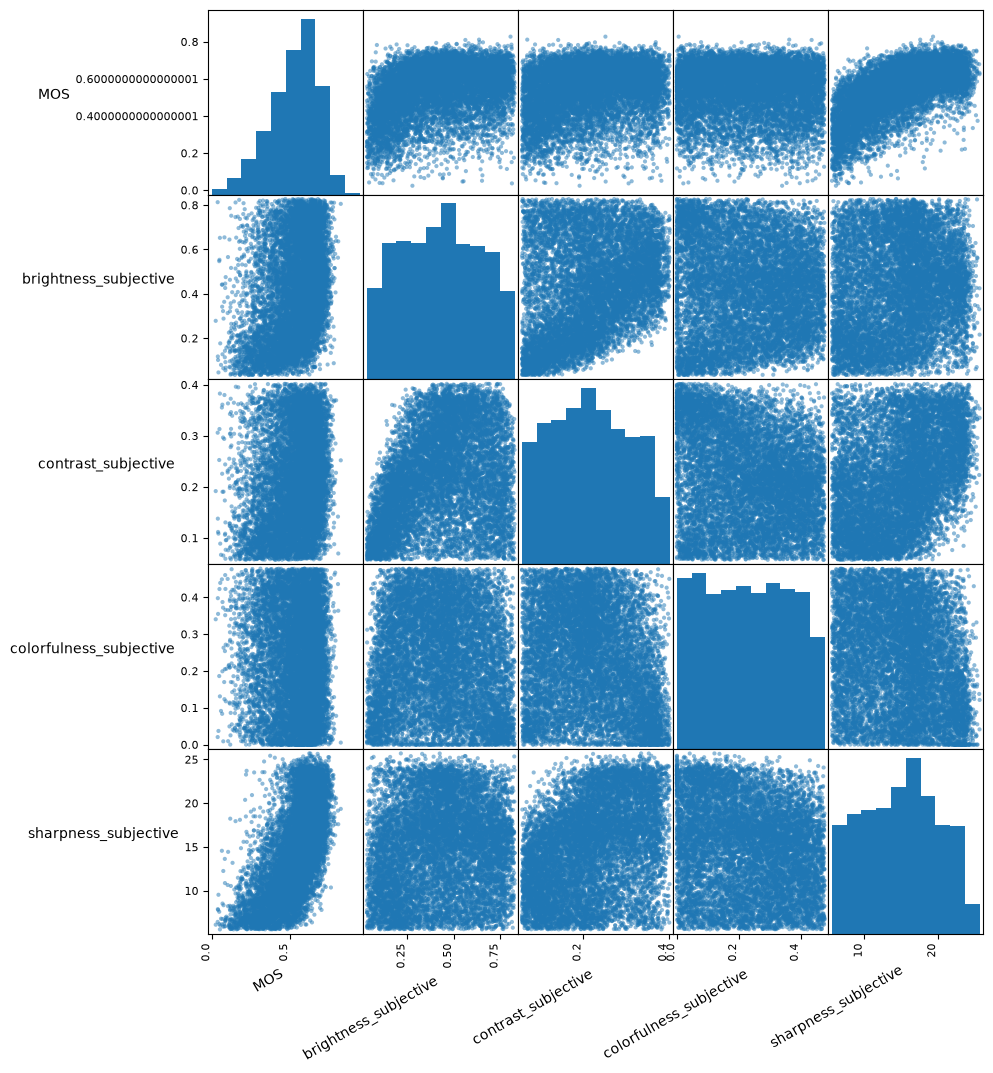

In [135]:
formatter = ticker.FormatStrFormatter('%.2f')

for cat in all_cats:
    axes = pd.plotting.scatter_matrix(df[cat], figsize=(10,12),diagonal='hist')
    for ax in axes.flatten():
        ax.xaxis.get_label().set_rotation(30)
        ax.yaxis.get_label().set_rotation(0)
        ax.xaxis.get_label().set_ha('right')
        ax.yaxis.get_label().set_ha('right')
        ax.tick_params(axis='x', rotation=90)
        ax.tick_params(axis='y', rotation=0)
        plt.setp(ax.get_xticklabels(), rotation=90, ha='right')
        plt.setp(ax.get_yticklabels(), rotation=0, ha='right')

        #ax.xaxis.set_major_formatter(formatter)
        #ax.yaxis.set_major_formatter(formatter)
    plt.show()

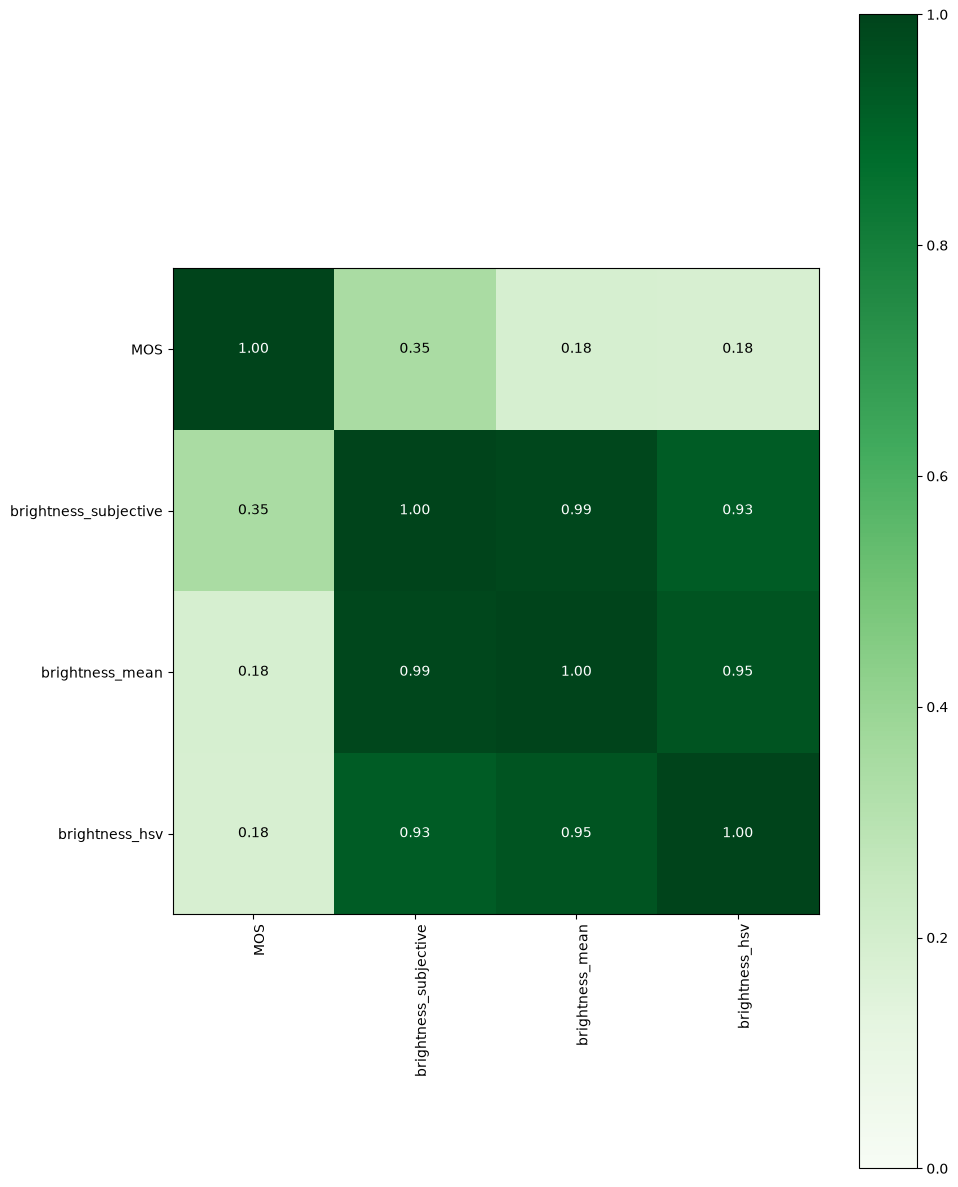

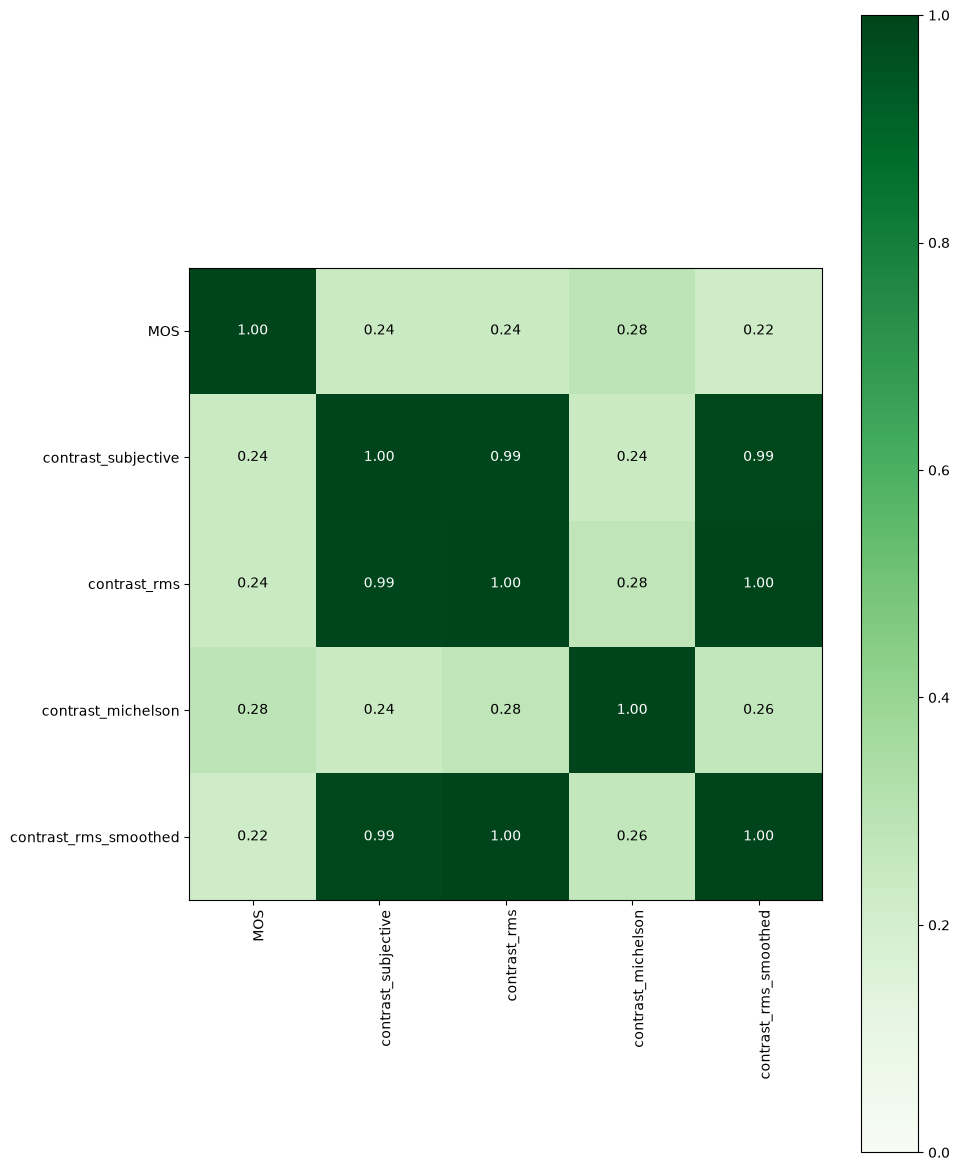

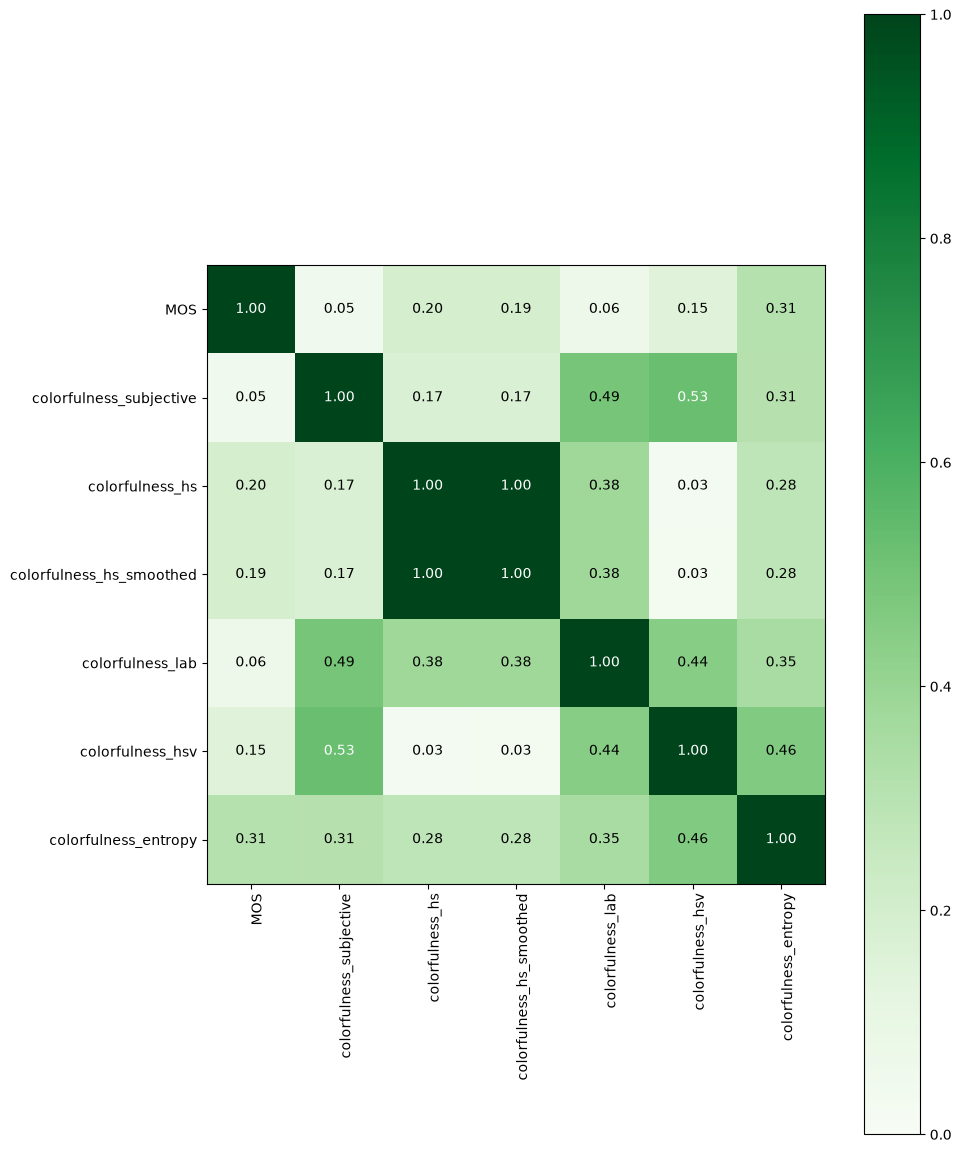

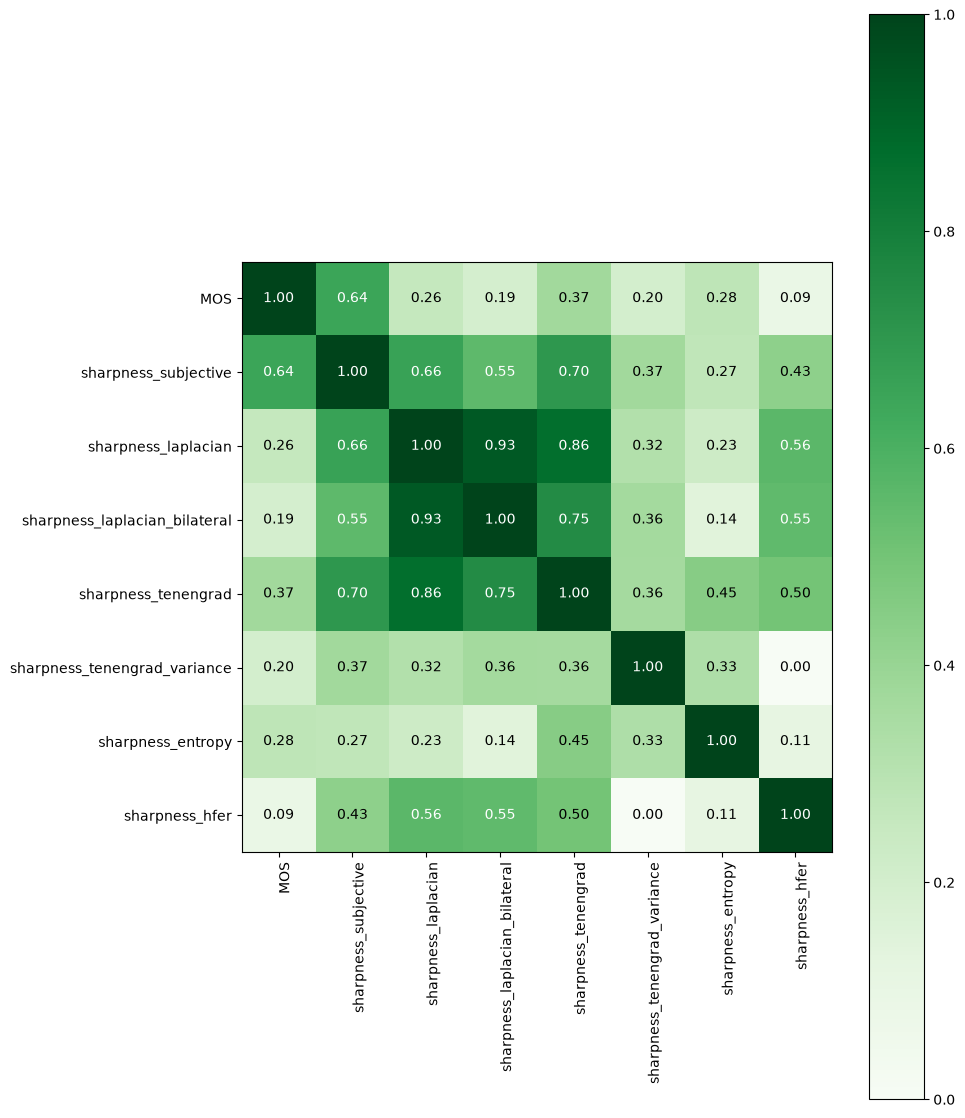

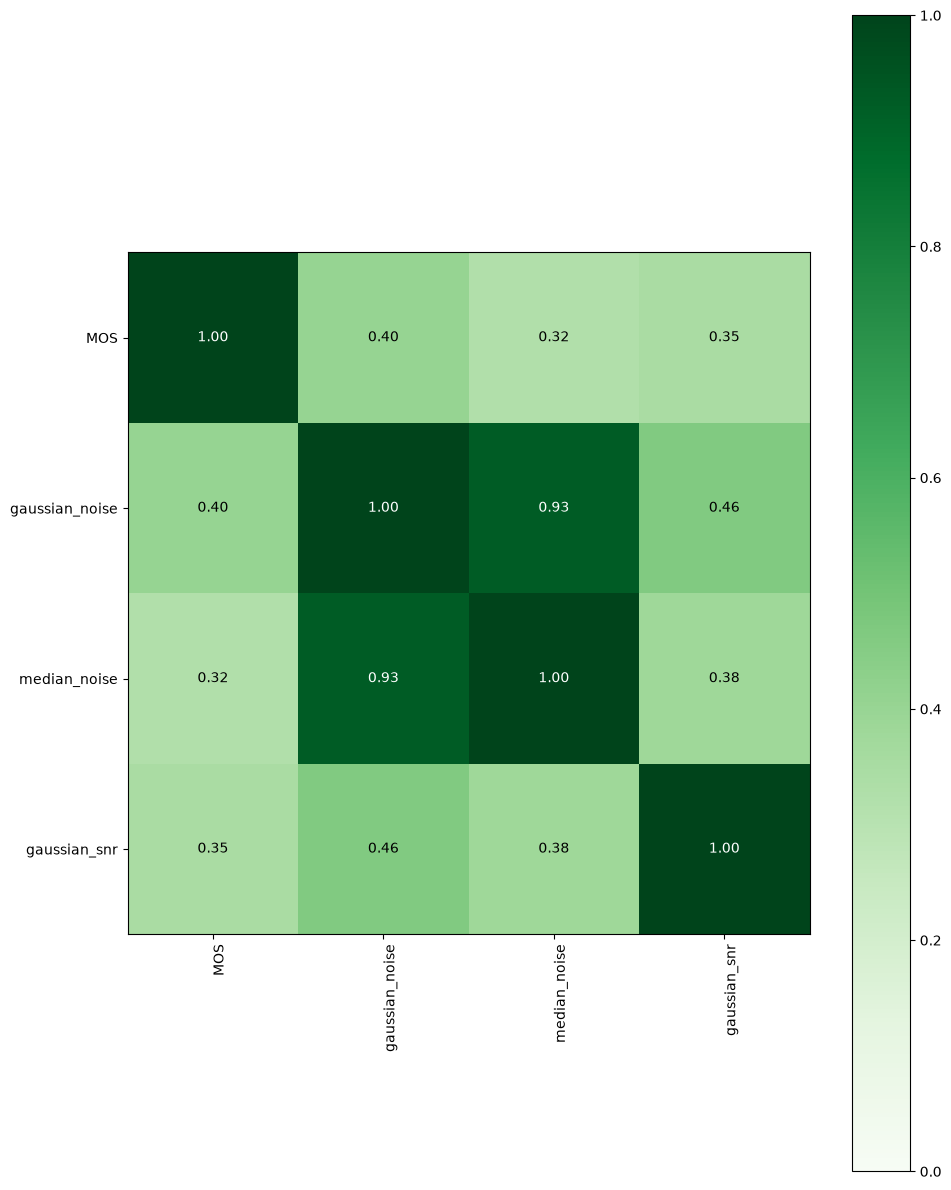

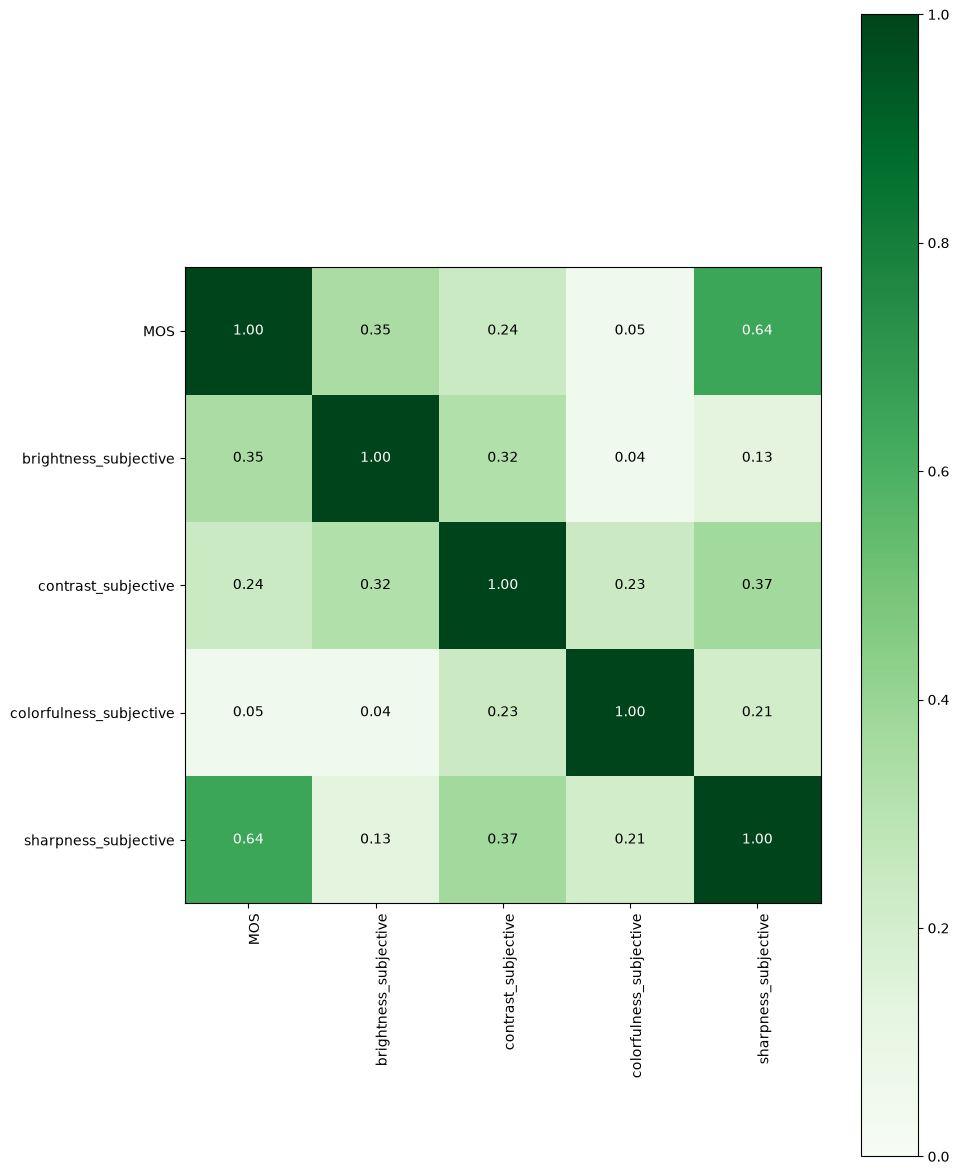

In [136]:
for cat in all_cats:
    corr_matrix = np.absolute(df[cat].corr(numeric_only=True))

    fig, ax = plt.subplots(figsize=(10,12))

    im = ax.imshow(corr_matrix.values, cmap='Greens', vmin=0, vmax=1, aspect='equal')

    fig.colorbar(im, ax=ax)

    ax.set_xticks(np.arange(len(corr_matrix.columns)))
    ax.set_yticks(np.arange(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns)
    ax.set_yticklabels(corr_matrix.columns)

    plt.setp(ax.get_xticklabels(), rotation=90, ha='right', rotation_mode='anchor')
    plt.setp(ax.get_yticklabels(), rotation=0, ha='right')

    for i in range(len(corr_matrix.index)):
        for j in range(len(corr_matrix.columns)):
            val = corr_matrix.iloc[i, j]
            
            text_color = "white" if abs(val) > 0.5 else "black"
            
            ax.text(j, i, f'{val:.2f}', 
                    ha='center', va='center', 
                    color=text_color, fontsize=10)
            
    plt.tight_layout()
    plt.show()

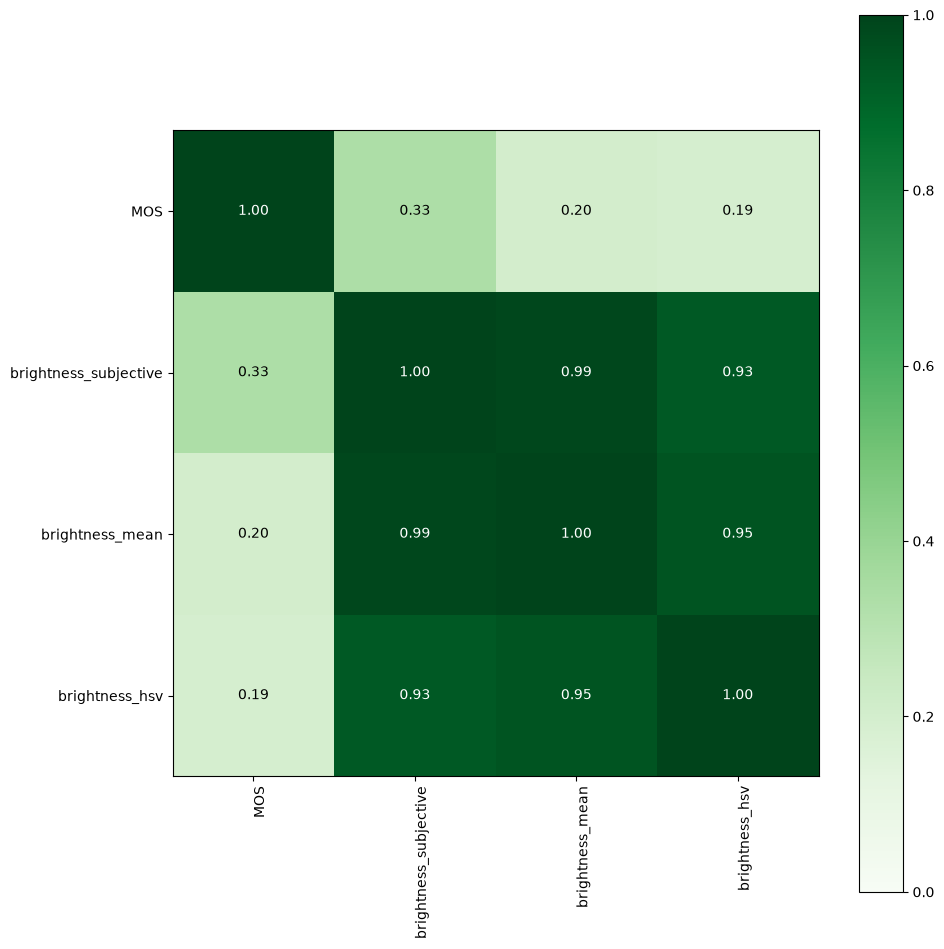

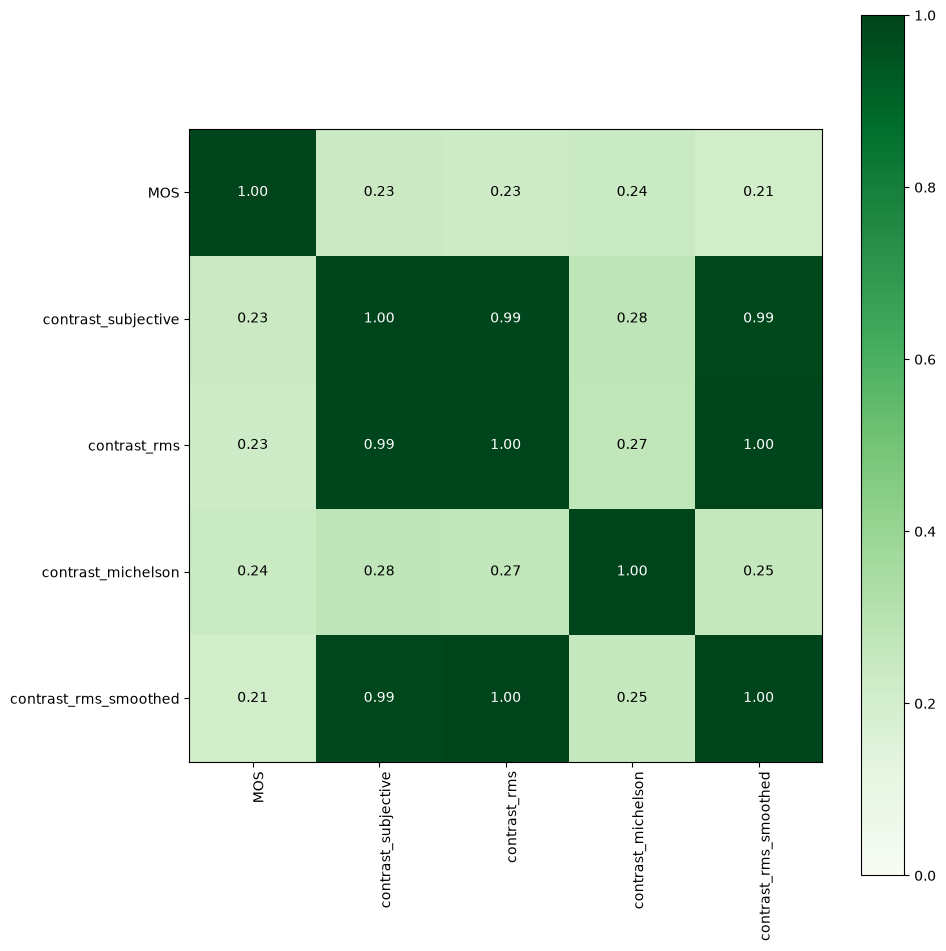

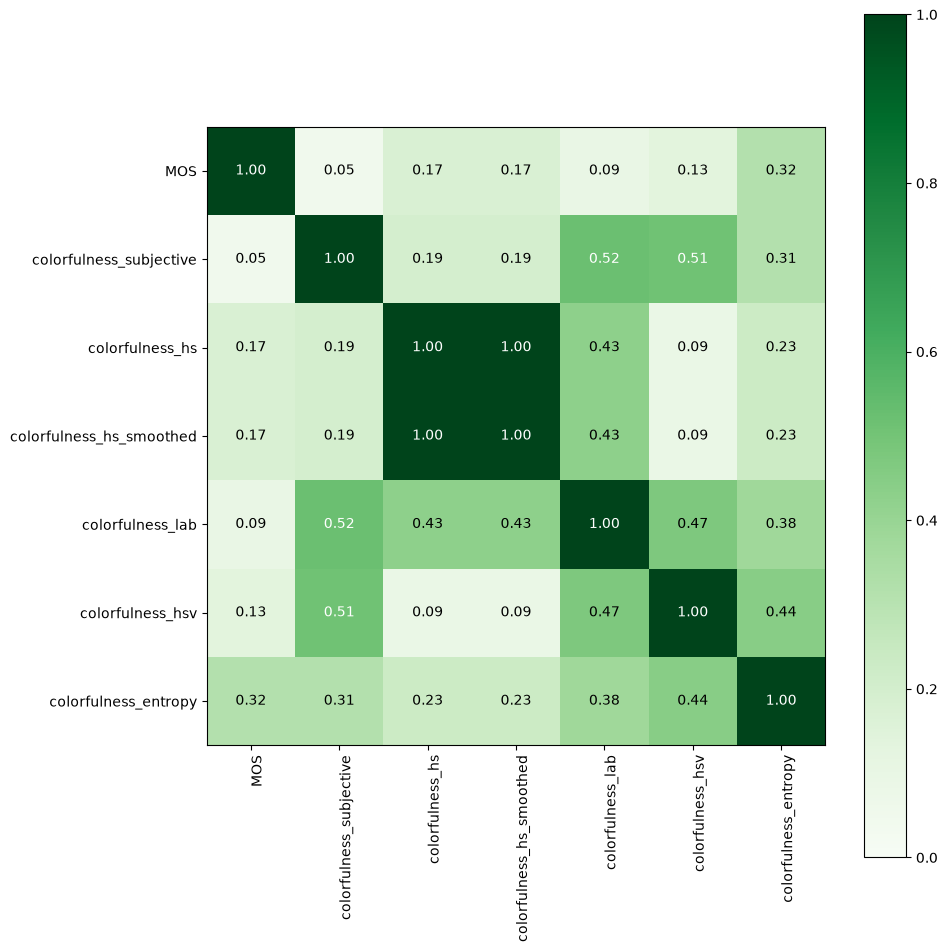

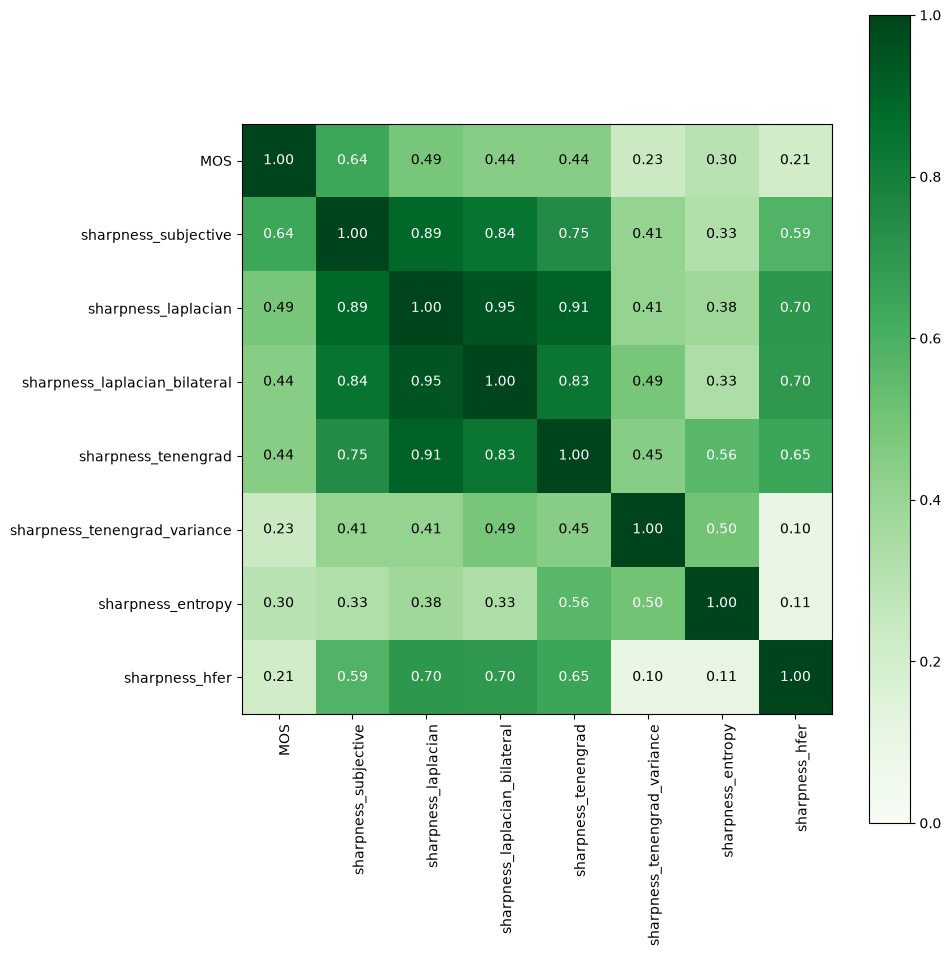

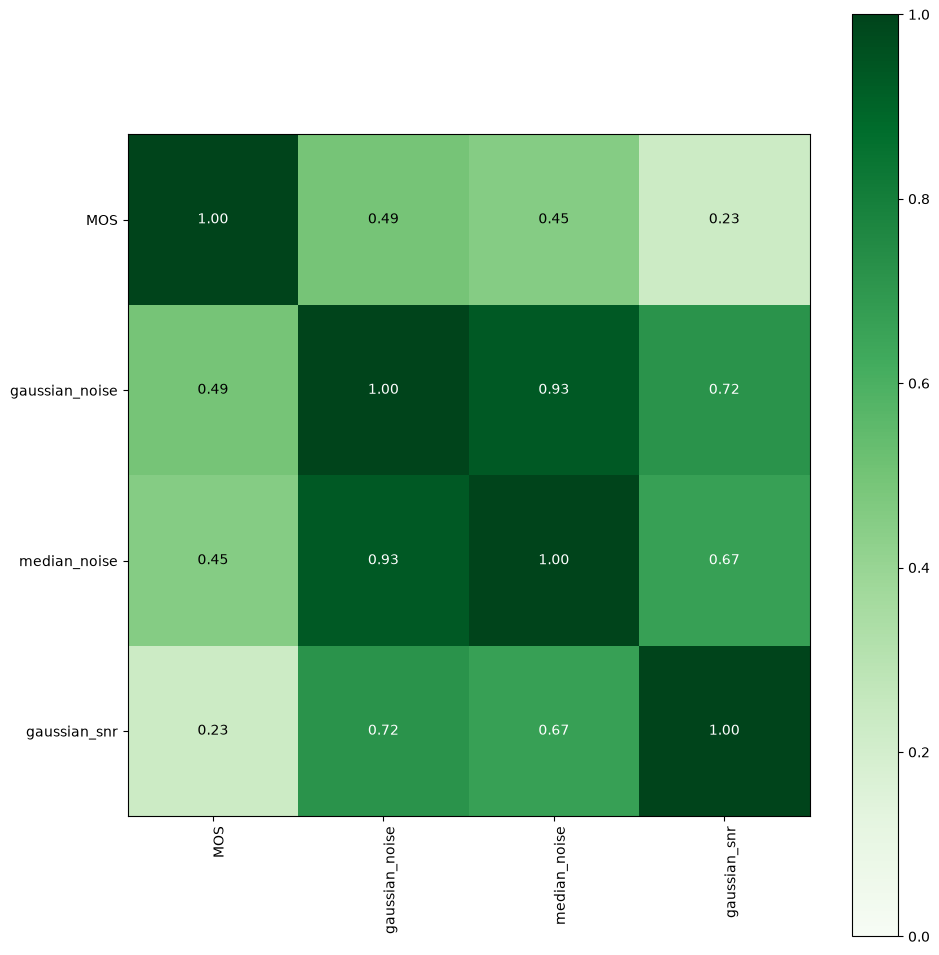

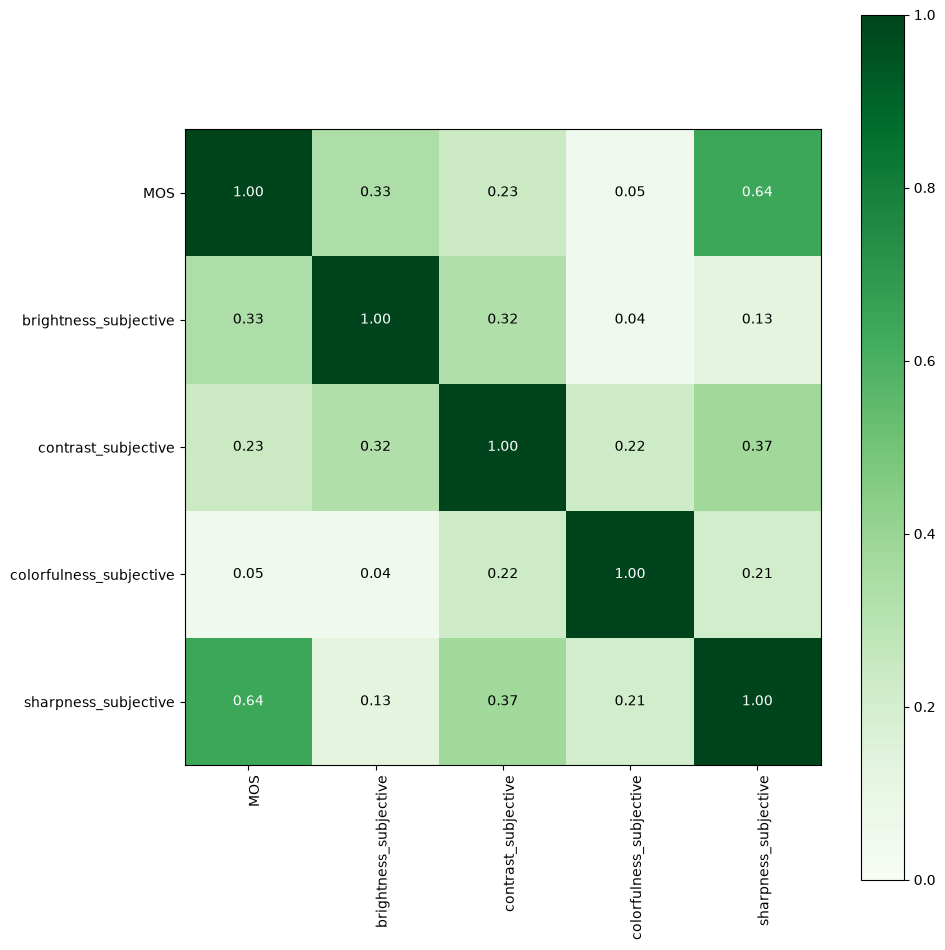

In [130]:
for cat in all_cats:
    corr_matrix = np.absolute(df[cat].corr(numeric_only=True, method='spearman'))

    fig, ax = plt.subplots(figsize=(10,10))

    im = ax.imshow(corr_matrix.values, cmap='Greens', vmin=0, vmax=1, aspect='equal')

    fig.colorbar(im, ax=ax)

    ax.set_xticks(np.arange(len(corr_matrix.columns)))
    ax.set_yticks(np.arange(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns)
    ax.set_yticklabels(corr_matrix.columns)

    plt.setp(ax.get_xticklabels(), rotation=90, ha='right', rotation_mode='anchor')
    plt.setp(ax.get_yticklabels(), rotation=0, ha='right')

    for i in range(len(corr_matrix.index)):
        for j in range(len(corr_matrix.columns)):
            val = corr_matrix.iloc[i, j]
            
            text_color = "white" if abs(val) > 0.5 else "black"
            
            ax.text(j, i, f'{val:.2f}', 
                    ha='center', va='center', 
                    color=text_color, fontsize=10)
            
    plt.tight_layout()
    plt.show()

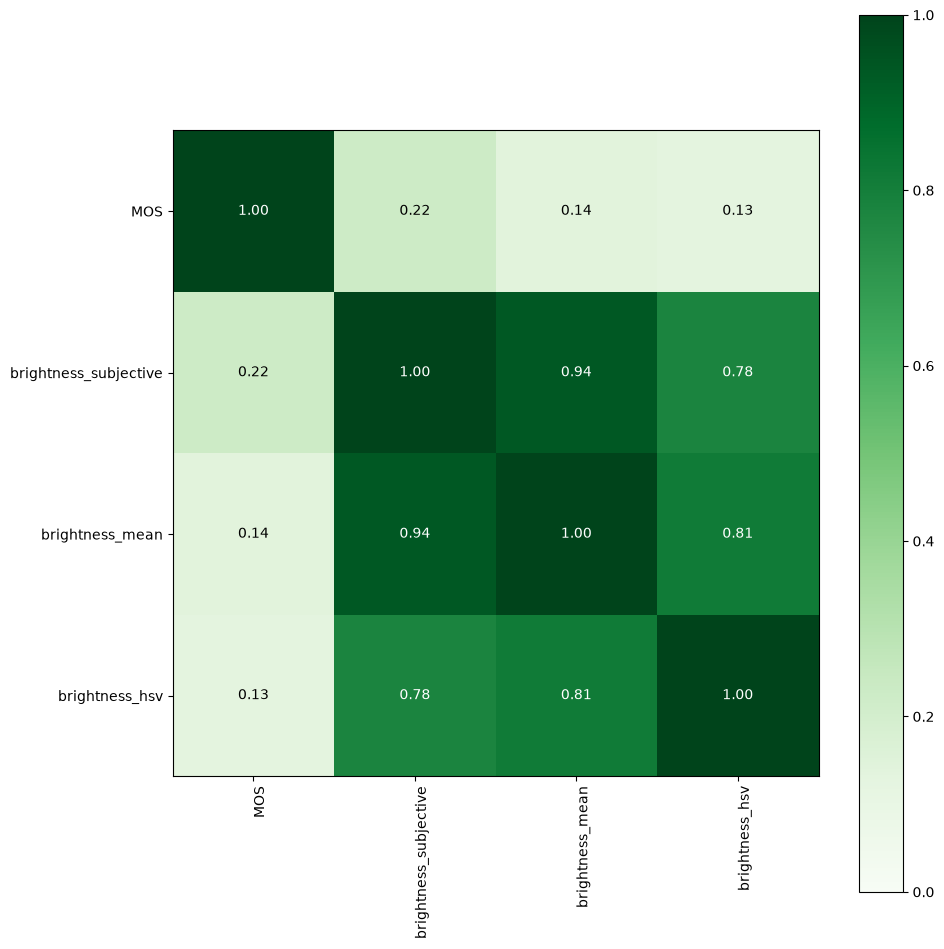

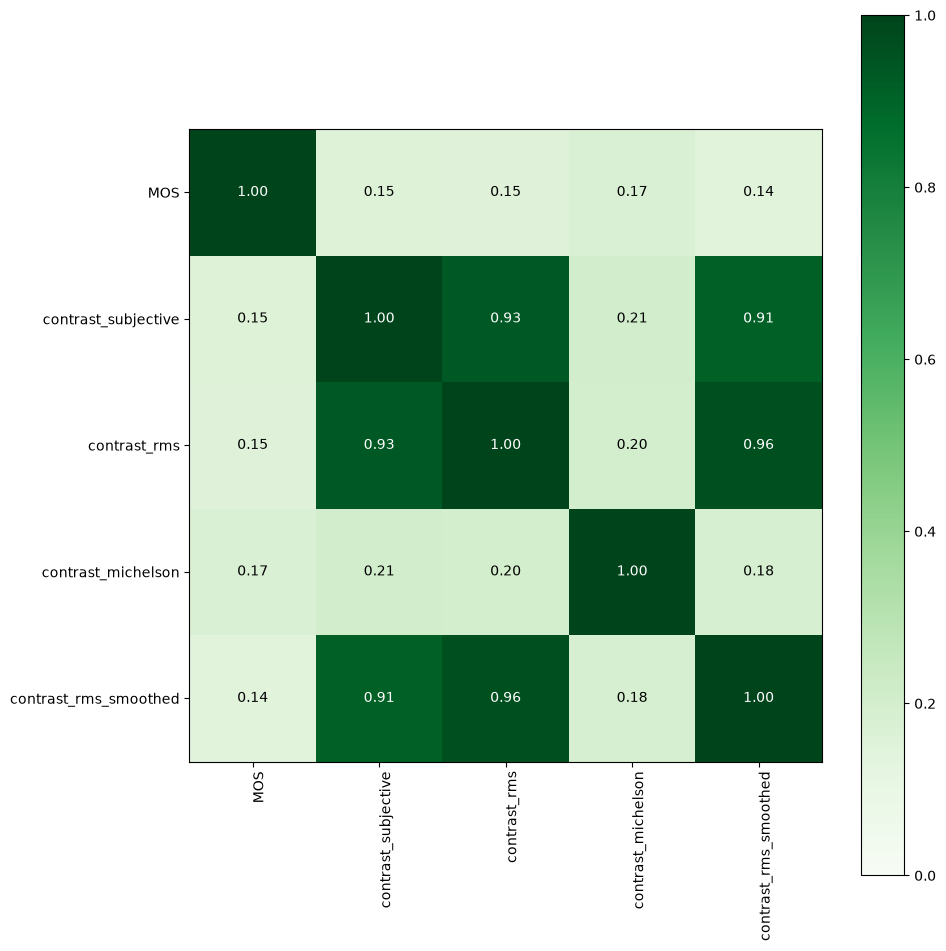

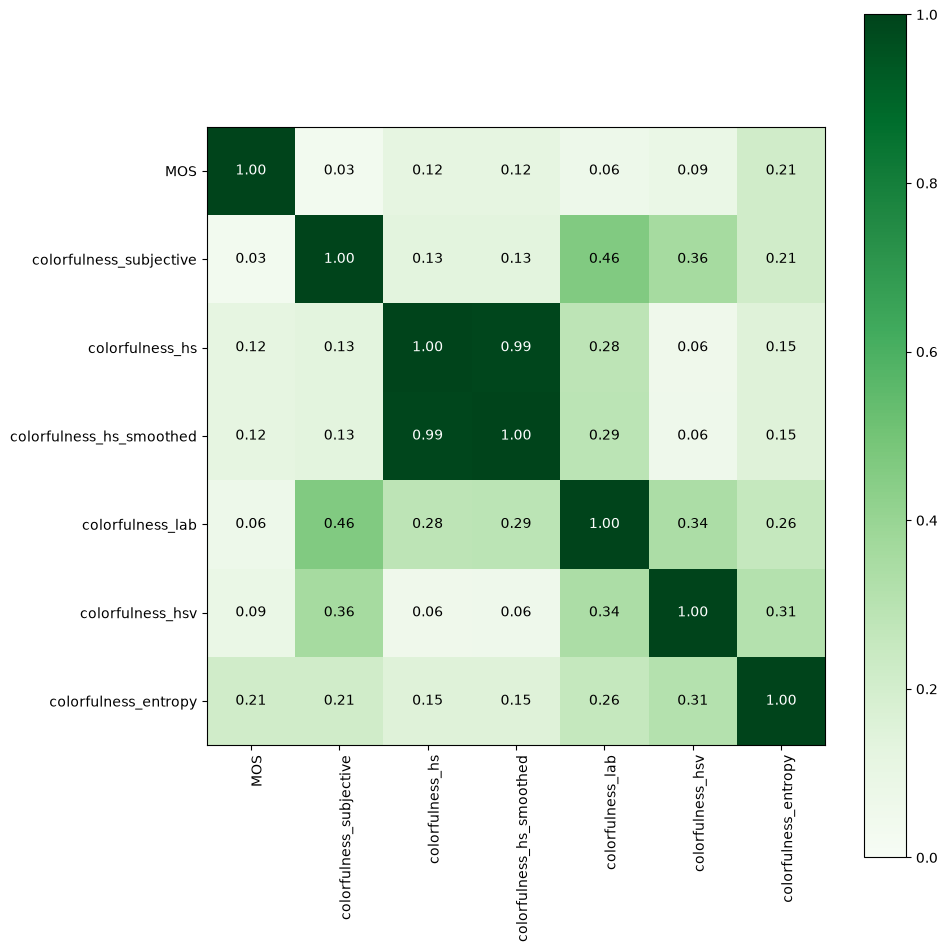

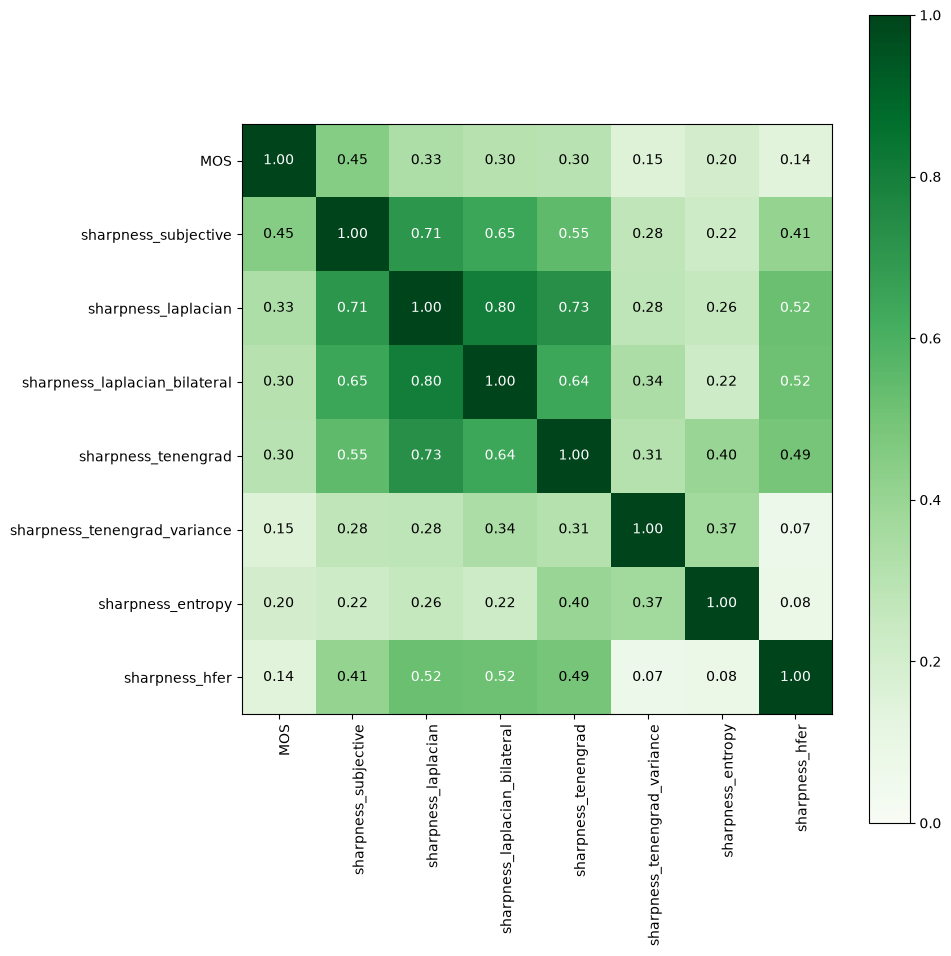

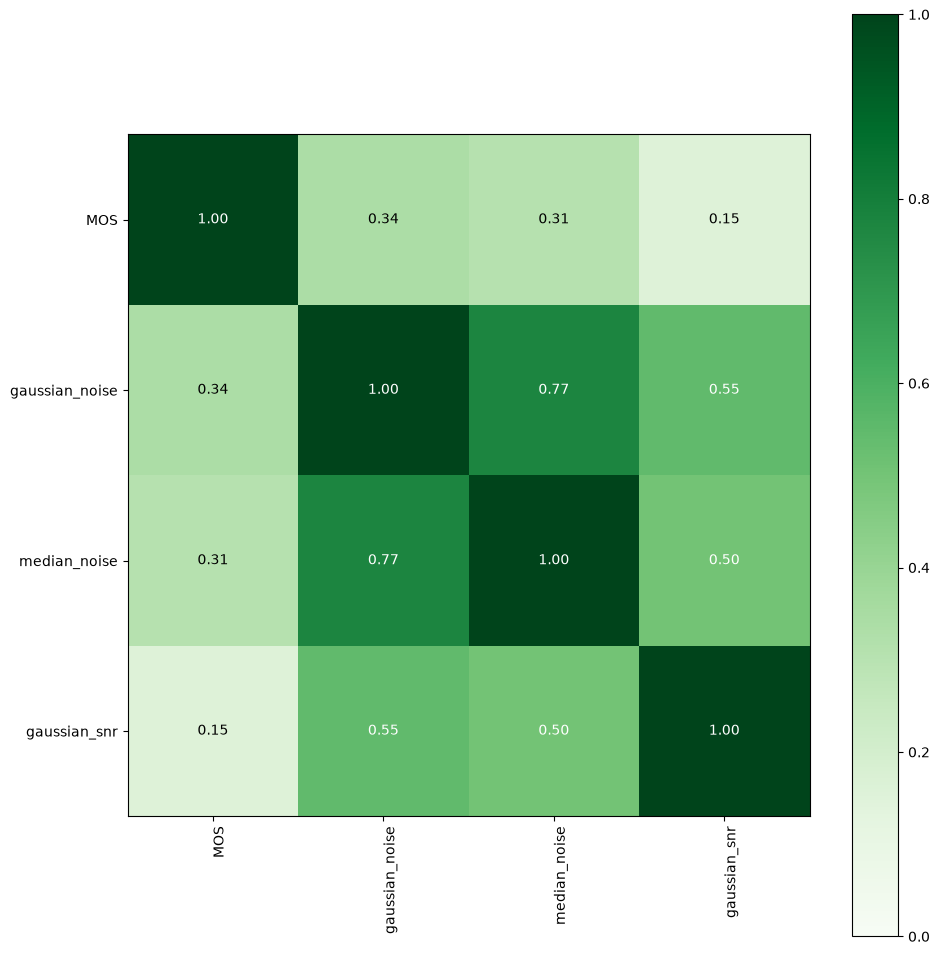

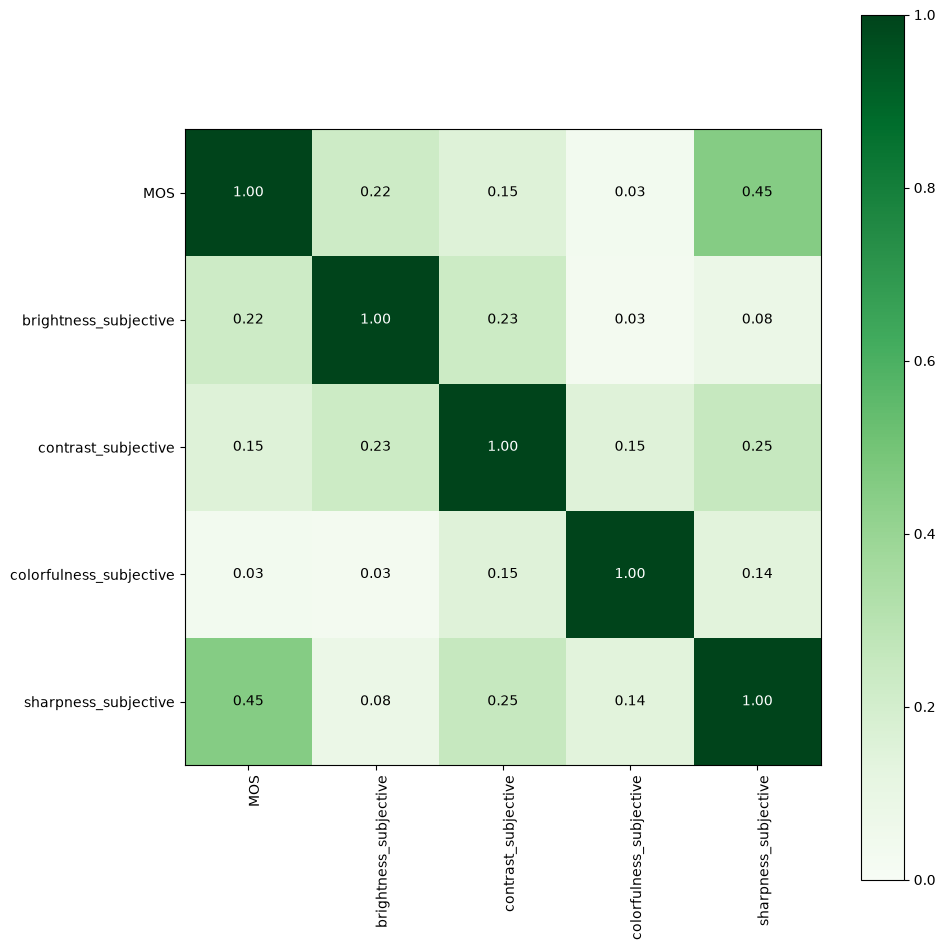

In [131]:
for cat in all_cats:
    corr_matrix = np.absolute(df[cat].corr(numeric_only=True, method='kendall'))

    fig, ax = plt.subplots(figsize=(10,10))

    im = ax.imshow(corr_matrix.values, cmap='Greens', vmin=0, vmax=1, aspect='equal')

    fig.colorbar(im, ax=ax)

    ax.set_xticks(np.arange(len(corr_matrix.columns)))
    ax.set_yticks(np.arange(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns)
    ax.set_yticklabels(corr_matrix.columns)

    plt.setp(ax.get_xticklabels(), rotation=90, ha='right', rotation_mode='anchor')
    plt.setp(ax.get_yticklabels(), rotation=0, ha='right')

    for i in range(len(corr_matrix.index)):
        for j in range(len(corr_matrix.columns)):
            val = corr_matrix.iloc[i, j]
            
            text_color = "white" if abs(val) > 0.5 else "black"
            
            ax.text(j, i, f'{val:.2f}', 
                    ha='center', va='center', 
                    color=text_color, fontsize=10)
            
    plt.tight_layout()
    plt.show()